<center><a href="https://www.nvidia.com/en-us/training/"><img src="https://dli-lms.s3.amazonaws.com/assets/general/DLI_Header_White.png" width="400" height="186" /></a></center>

# 3. Optimizations

Currently, the model is experiencing the [checkerboard problem](https://distill.pub/2016/deconv-checkerboard/). 
<br/>
<center><img src="images/shoe_maybe.png" /></center>
<br/>
Thankfully, we have a few tricks up our generated T-shirt sleeve to resolve this and generally improve the performance of the model.
<br/>
<br/>

#### Learning Objectives

The goals of this notebook are to:
* Implement Group Normalization
* Implement GELU
* Implement Rearrange Pooling
* Implement Sinusoidal Position Embeddings
* Define a reverse diffusion function to emulate `p`
* Attempt to generate articles of clothing (again)

Like before, let's use fashionMIST to experiment:

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.optim import Adam

# Visualization tools
import matplotlib.pyplot as plt
from torchview import draw_graph
import graphviz
from IPython.display import Image

# User defined libraries
from utils import other_utils
from utils import ddpm_utils

IMG_SIZE = 16
IMG_CH = 1
BATCH_SIZE = 128
data, dataloader = other_utils.load_transformed_fashionMNIST(IMG_SIZE, BATCH_SIZE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

100%|██████████| 26421880/26421880 [00:02<00:00, 13200593.36it/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29515/29515 [00:00<00:00, 329943.72it/s]


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 4422102/4422102 [00:00<00:00, 6059821.18it/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5148/5148 [00:00<00:00, 11005238.02it/s]

Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



We have created a [ddpm_util.py](ddpm_utils.py) with a `DDPM` class to group our diffusion functions. Let's use it to set up the same Beta schedule as what we used previously.

In [2]:
nrows = 10
ncols = 15

T = nrows * ncols
B_start = 0.0001
B_end = 0.02
B = torch.linspace(B_start, B_end, T).to(device)
ddpm = ddpm_utils.DDPM(B, device)

## 3.1 Group Normalization and GELU

The first improvement we will look at is optimizing our standard convolution process. We will be reusing this block many times throughout our neural network, so it is an important piece to get right.

### 3.1.1 Group Normalization

## HS NOTE on batch norm:
You're right to connect Batch Normalization with z-scores. The core idea of normalizing in Batch Normalization is, in fact, to calculate a z-score for the activations of each neuron or, in the case of convolutional layers, each channel.

Here's how it works:

1.  **Calculate Mean ($\mu$) across the Batch:** For a given neuron or channel, Batch Normalization first calculates the mean of its activations across all the samples in the current mini-batch.
    Let's say for a specific channel, the activations in a mini-batch are $x_1, x_2, ..., x_m$, where $m$ is the batch size.
    The mean ($\mu$) is calculated as:
    $$\mu = \frac{1}{m} \sum_{i=1}^{m} x_i$$

2.  **Calculate Standard Deviation ($\sigma$) across the Batch:** Next, it calculates the standard deviation of these activations across the same mini-batch.
    The variance ($\sigma^2$) is calculated as:
    $$\sigma^2 = \frac{1}{m} \sum_{i=1}^{m} (x_i - \mu)^2$$
    And the standard deviation ($\sigma$) is the square root of the variance:
    $$\sigma = \sqrt{\sigma^2 + \epsilon}$$
    A small constant, $\epsilon$ (epsilon), is added to the variance before taking the square root. This is a crucial step for numerical stability, ensuring that you don't try to divide by zero if the variance happens to be zero (e.g., if all activations in the batch are the same).

3.  **Calculate the Z-score (Normalization):** With the mean ($\mu$) and standard deviation ($\sigma$) computed from the batch, each activation ($x_i$) for that neuron/channel within the mini-batch is then transformed into a z-score. The formula for a z-score is:
    $$z_i = \frac{x_i - \mu}{\sigma}$$
    This normalized output $z_i$ will have a mean of approximately 0 and a standard deviation of approximately 1 for the current batch.

**Why this is like a Z-score:**
A z-score fundamentally tells you how many standard deviations an individual data point is away from the mean of its distribution. This is precisely what the normalization step in Batch Normalization does for each activation, using the statistics (mean and standard deviation) of the current mini-batch.

**Beyond the Z-score:**
It's important to note that Batch Normalization usually includes two additional learnable parameters per neuron/channel:
* A scaling factor, $\gamma$ (gamma)
* A shifting factor, $\beta$ (beta)

After the z-score calculation, the normalized value $z_i$ is further transformed:
$$\text{BN}(x_i) = \gamma z_i + \beta$$
These parameters allow the network to learn the optimal scale and mean for the activations. In essence, the network can learn to "undo" the normalization to some extent if that's beneficial for the representation power of the layer. So, while the core is a z-score transformation, $\gamma$ and $\beta$ give the layer flexibility to adjust the distribution as needed during training.

Your slide is correct: the conversion to a z-score using the batch's mean and standard deviation is the fundamental normalization step. The ineffectiveness for small batch sizes arises because the calculated mean and standard deviation from a very small batch might not be representative of the overall data distribution, leading to noisy and unstable estimates, which can hinder the training process.

[Batch Normalization](https://towardsdatascience.com/batch-normalization-in-3-levels-of-understanding-14c2da90a338) converts the output of each kernel channel to a [z-score](https://www.nlm.nih.gov/oet/ed/stats/02-910.html). It does this by calculating the mean and standard deviation across a batch of inputs. This is ineffective if the batch size is small.

On the other hand, [Group Normalization](https://arxiv.org/pdf/1803.08494.pdf) normalizes the output of a group of kernels for each sample image, effectively "grouping" a set of features.

<center><img src="images/groupnorm.png" /></center>

Considering color images have multiple color channels, this can have an interesting impact on the output colors of generated images. Try experimenting to see the effect!

Learn more about normalization techniques in this [blog post](https://medium.com/techspace-usict/normalization-techniques-in-deep-neural-networks-9121bf100d8) by Aakash Bindal.

### 3.1.2 GELU

[ReLU](https://www.kaggle.com/code/dansbecker/rectified-linear-units-relu-in-deep-learning) is a popular choice for an activation function because it is computationally quick and easy to calculate the gradient for. Unfortunately, it isn't perfect. When the bias term becomes largely negative, a ReLU neuron ["dies"](https://datascience.stackexchange.com/questions/5706/what-is-the-dying-relu-problem-in-neural-networks) because both its output and gradient are zero.

At a slight cost in computational power, [GELU](https://arxiv.org/pdf/1606.08415.pdf) seeks to rectify the rectified linear unit by mimicking the shape of the ReLU function while avoiding a zero gradient.

In this small example with FashionMNIST, it is unlikely we will see any dead neurons. However, the larger a model gets, the more likely it can face the dying ReLU phenomenon.

In [4]:
class GELUConvBlock(nn.Module):
    def __init__(
        self, in_ch, out_ch, group_size):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, 1, 1),
            nn.GroupNorm(group_size, out_ch),
            nn.GELU()
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

## 3.2 Rearrange pooling

## HS note on einops

You're absolutely right, the order of `h` and `p1` within the parentheses `()` in the `einops` pattern string is critical and dictates how the rows (or elements along that dimension) are grouped when `p1` is moved to the channel dimension.

Let's break down what each of these `Rearrange` operations means, using your explanation as a guide, and solidify it with a small example. Assume `p1=2` for both.

**Common Goal:**
Both operations take an input tensor (let's say with dimensions `channels, original_height, width`) and transform it. The `p1=2` part means that the `original_height` will be effectively halved to a new height `h`, and the information from this halving process will be used to double the number of channels (since `p1=2` contributes a factor of 2 to the new channel dimension `(c p1)`).

**Case 1: `Rearrange("c (h p1) w -> (c p1) h w", p1=2)`**

* **Input Pattern: `c (h p1) w`**
    * `c`: Original channels.
    * `(h p1)`: This tells `einops` to view the original height dimension as being composed of `h` blocks, where *each block has `p1` (i.e., 2) consecutive elements*.
        * `original_height = h * p1`. So, the new height `h` will be `original_height / 2`.
        * `p1` represents the index *within* one of these 2-element blocks (0 or 1).
    * `w`: Width.
* **Output Pattern: `(c p1) h w`**
    * `(c p1)`: The new channel dimension is formed by taking the original channels `c` and combining them with the `p1` part.
    * `h`: The new, smaller height.
* **Your Explanation: "If we put the part variable p1 after the height dimension h, it lets einops know that every p1th row should be grouped."**
    * This is correct. Let's see why with `p1=2`.
    * Consider an input height with rows: `R0, R1, R2, R3, R4, R5, ...`
    * `einops` sees this as:
        * Block 0 (`h=0`): `(R0, R1)` (where `R0` is at `p1_index=0`, `R1` is at `p1_index=1`)
        * Block 1 (`h=1`): `(R2, R3)` (where `R2` is at `p1_index=0`, `R3` is at `p1_index=1`)
        * Block 2 (`h=2`): `(R4, R5)` (where `R4` is at `p1_index=0`, `R5` is at `p1_index=1`)
        * And so on.
    * When `p1` moves to the channel dimension:
        * One set of new channels (say, for `p1_index=0`) will be formed by taking all the 0th elements from these blocks: `R0, R2, R4, ...` (These are, indeed, every 2nd row starting from the 0th).
        * Another set of new channels (for `p1_index=1`) will be formed by taking all the 1st elements from these blocks: `R1, R3, R5, ...` (These are every 2nd row starting from the 1st).
    * This is "interleaved grouping": you're picking rows with a stride.

**Case 2: `Rearrange("c (p1 h) w -> (c p1) h w", p1=2)`**

* **Input Pattern: `c (p1 h) w`**
    * `c`: Original channels.
    * `(p1 h)`: This tells `einops` to view the original height dimension as being composed of `p1` (i.e., 2) major sections (or blocks), where *each section has `h` consecutive elements*.
        * `original_height = p1 * h`. So, the new height `h` will be `original_height / 2`.
        * `p1` represents the index *of these major sections* (0 or 1).
    * `w`: Width.
* **Output Pattern: `(c p1) h w`** (Same output structure as Case 1, but the data populating it will be different due to the input interpretation).
* **Your Explanation: "On the other hand, if we put p1 before h, it tells einops group the first p1 rows, then the next p1 rows, and so on."** (Here, "first p1 rows" means the first block of `h` rows corresponding to `p1_index=0`, then the next block of `h` rows for `p1_index=1`, if `p1` were the number of blocks. Given `p1=2` is the factor, this means the first `h` rows form one group for the new channel, and the next `h` rows form the second group for the new channel.)
    * This is correct. Let's see why with `p1=2`.
    * The original height is split into `p1=2` large sections.
        * Section 0 (`p1_index=0`): `R0, R1, ..., R(h-1)`
        * Section 1 (`p1_index=1`): `R(h), R(h+1), ..., R(original_height-1)`
    * When `p1` moves to the channel dimension:
        * One set of new channels (for `p1_index=0`) will be formed by taking all rows from the first section: `R0, R1, ..., R(h-1)`.
        * Another set of new channels (for `p1_index=1`) will be formed by taking all rows from the second section: `R(h), R(h+1), ..., R(original_height-1)`.
    * This is "consecutive block grouping": you're taking the first chunk of `h` rows, then the second chunk of `h` rows, and these chunks directly populate the new channel parts.

**In essence:**

* **`c (h p1) w -> (c p1) h w` (p1 as inner dimension size):**
    Imagine the height dimension laid out. This pattern groups elements *within* small, consecutive blocks of size `p1`. When these `p1` elements are moved to the channel dimension, it results in an *interleaved* selection from the original rows.
    Output new\_channel\_0 gets: original\_row\_0, original\_row\_p1, original\_row\_2\*p1, ...
    Output new\_channel\_1 gets: original\_row\_1, original\_row\_(p1+1), original\_row\_(2\*p1+1), ...

* **`c (p1 h) w -> (c p1) h w` (p1 as outer dimension count):**
    Imagine the height dimension split into `p1` large, consecutive sections. This pattern takes each of these entire sections and maps them to a new part of the channel dimension. This results in *consecutive blocks* of original rows forming the new channel information.
    Output new\_channel\_0 gets: original\_row\_0, original\_row\_1, ..., original\_row\_(h-1)
    Output new\_channel\_1 gets: original\_row\_h, original\_row\_(h+1), ..., original\_row\_(2h-1)

Your understanding and the slide's explanation accurately capture this important distinction in `einops`. It's a powerful feature for precisely controlling how data is reshaped.

In the previous notebook, we used [Max Pooling](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html) to halve the size of our latent image, but is that the best technique? There are [many types of pooling layers](https://pytorch.org/docs/stable/nn.html#pooling-layers) including Min Pooling and Average Pooling. How about we let the neural network decide what is important.

Enter the [einops](https://einops.rocks/1-einops-basics/) library and the [Rearrange](https://einops.rocks/api/rearrange/) layer. We can assign each layer a variable and use that to rearrange our values. Additionally, we can use parentheses `()` to identify a set of variables that are multiplied together.

For example, in the code block below, we have:

`Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2)`

* `b` is our batch dimension
* `c` is our channel dimension
* `h` is our height dimension
* `w` is our width dimension

We also have a `p1` and `p2` value that are both equal to `2`. The left portion of the equation before the arrow is saying "split the height and width dimensions in half. The right portion of the equation after the arrow is saying "stack the split dimensions along the channel dimension".

The code block below sets up a `test_image` to practice on. Try swapping `h` with `p1` on the left side of the arrow. What happens? How about when `w` and `p2` are swapped? What happens when `p1` is set to `3` instead of `2`?

In [8]:
from einops.layers.torch import Rearrange

rearrange = Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2)

test_image = [
    [
        [
            [1, 2, 3, 4, 5, 6],
            [7, 8, 9, 10, 11, 12],
            [13, 14, 15, 16, 17, 18],
            [19, 20, 21, 22, 23, 24],
            [25, 26, 27, 28, 29, 30],
            [31, 32, 33, 34, 35, 36],
        ]
    ]
]
test_image = torch.tensor(test_image)
print(test_image)
output = rearrange(test_image)
output

tensor([[[[ 1,  2,  3,  4,  5,  6],
          [ 7,  8,  9, 10, 11, 12],
          [13, 14, 15, 16, 17, 18],
          [19, 20, 21, 22, 23, 24],
          [25, 26, 27, 28, 29, 30],
          [31, 32, 33, 34, 35, 36]]]])


tensor([[[[ 1,  3,  5],
          [13, 15, 17],
          [25, 27, 29]],

         [[ 2,  4,  6],
          [14, 16, 18],
          [26, 28, 30]],

         [[ 7,  9, 11],
          [19, 21, 23],
          [31, 33, 35]],

         [[ 8, 10, 12],
          [20, 22, 24],
          [32, 34, 36]]]])

Next, we can pass this through our `GELUConvBlock` to let the neural network decide how it wants to weigh the values within our "pool". Notice the `4*in_chs` as a parameter of the `GELUConvBlock`? This is because the channel dimension is now p1 * p2 larger.

In [9]:
class RearrangePoolBlock(nn.Module):
    def __init__(self, in_chs, group_size):
        super().__init__()
        self.rearrange = Rearrange("b c (h p1) (w p2) -> b (c p1 p2) h w", p1=2, p2=2)
        self.conv = GELUConvBlock(4 * in_chs, in_chs, group_size)

    def forward(self, x):
        x = self.rearrange(x)
        return self.conv(x)

We now have the components to redefine our `DownBlock`s and `UpBlock`s. Multiple `GELUConvBlock`s have been added to help combat the checkerboard problem.

In [10]:
class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(DownBlock, self).__init__()
        layers = [
            GELUConvBlock(in_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            RearrangePoolBlock(out_chs, group_size)
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

In [11]:
class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super(UpBlock, self).__init__()
        layers = [
            nn.ConvTranspose2d(2 * in_chs, out_chs, 2, 2),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
            GELUConvBlock(out_chs, out_chs, group_size),
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x

## 3.3 Time Embeddings

The better the model understands the timestep it is in for the reverse diffusion process, the better it will be able to correctly identify the added noise. In the previous notebook, we created an embedding for `t/T`. Can we help the model interpret this better?

Before diffusion models, this was a problem that plagued natural language processing. For long dialogues, how can we capture where we are? The goal was to find a way to uniquely represent a large range of discrete numbers with a small number of continuous numbers. Using a single float is ineffective since the neural network will interpret timesteps as continuous rather than discrete. [Researchers](https://arxiv.org/pdf/1706.03762.pdf) ultimately settled on a sum of sines and cosines.

For an excellent explanation for why this works and how this technique was likely developed, please refer to Jonathan Kernes' [Master Positional Encoding](https://towardsdatascience.com/master-positional-encoding-part-i-63c05d90a0c3).

In [12]:
import math

class SinusoidalPositionEmbedBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=-1)
        return embeddings

In [13]:
class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super(EmbedBlock, self).__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1))
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(-1, self.input_dim)
        return self.model(x)

## 3.4 Residual Connections

The last trick to eliminate the checkerboard problem is to add more residual or skip connections. We can create a `ResidualConvBlock` for our initial convolution. We could add residual connections in other places as well, such as within our "DownBlocks" and "UpBlocks".

In [14]:
class ResidualConvBlock(nn.Module):
    def __init__(self, in_chs, out_chs, group_size):
        super().__init__()
        self.conv1 = GELUConvBlock(in_chs, out_chs, group_size)
        self.conv2 = GELUConvBlock(out_chs, out_chs, group_size)

    def forward(self, x):
        x1 = self.conv1(x)
        x2 = self.conv2(x1)
        out = x1 + x2
        return out

Below is the updated model. Notice the change at the very last line? Another skip connection has been added from the output of our `ResidualConvBlock` to the final `self.out` block. This connection is surprisingly powerful, and of all the changes listed above, had the biggest influence on the checkerboard problem for this dataset.

In [15]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        img_chs = IMG_CH
        down_chs = (64, 64, 128)
        up_chs = down_chs[::-1]  # Reverse of the down channels
        latent_image_size = IMG_SIZE // 4 # 2 ** (len(down_chs) - 1)
        t_dim = 8
        group_size_base = 4
        small_group_size = 2 * group_size_base # New
        big_group_size = 8 * group_size_base  # New
        

        # Inital convolution
        self.down0 = ResidualConvBlock(img_chs, down_chs[0], small_group_size) # New

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1], big_group_size) # New
        self.down2 = DownBlock(down_chs[1], down_chs[2], big_group_size) # New
        self.to_vec = nn.Sequential(nn.Flatten(), nn.GELU())
        
        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2]*latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2]*latent_image_size**2),
            nn.ReLU()
        )

        self.sinusoidaltime = SinusoidalPositionEmbedBlock(t_dim) # New
        self.temb_1 = EmbedBlock(t_dim, up_chs[0])
        self.temb_2 = EmbedBlock(t_dim, up_chs[1])
        
        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            GELUConvBlock(up_chs[0], up_chs[0], big_group_size) # New
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1], big_group_size) # New
        self.up2 = UpBlock(up_chs[1], up_chs[2], big_group_size) # New

        # Match output channels and one last concatenation
        self.out = nn.Sequential(
            nn.Conv2d(2 * up_chs[-1], up_chs[-1], 3, 1, 1),
            nn.GroupNorm(small_group_size, up_chs[-1]), # New
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1)
        )

    def forward(self, x, t):
        down0 = self.down0(x)
        down1 = self.down1(down0)
        down2 = self.down2(down1)
        latent_vec = self.to_vec(down2)
        
        latent_vec = self.dense_emb(latent_vec)
        t = t.float() / T  # Convert from [0, T] to [0, 1]
        t = self.sinusoidaltime(t) # New
        temb_1 = self.temb_1(t)
        temb_2 = self.temb_2(t)

        up0 = self.up0(latent_vec)
        up1 = self.up1(up0+temb_1, down2)
        up2 = self.up2(up1+temb_2, down1)
        return self.out(torch.cat((up2, down0), 1)) # New

In [16]:
model = UNet()
print("Num params: ", sum(p.numel() for p in model.parameters()))
model = torch.compile(model.to(device))

Num params:  1979777


Finally, it's time to train the model. Let's see if all these changes made a difference.

Epoch 0 | step 000 Loss: 1.1335384845733643 


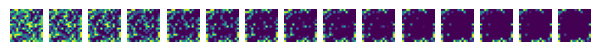

Epoch 0 | step 100 Loss: 0.16960984468460083 


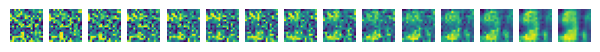

Epoch 0 | step 200 Loss: 0.12893438339233398 


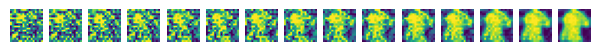

Epoch 0 | step 300 Loss: 0.13025423884391785 


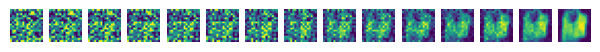

Epoch 0 | step 400 Loss: 0.13269105553627014 


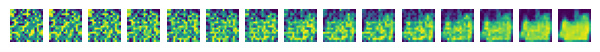

Epoch 0 | step 500 Loss: 0.11297152936458588 


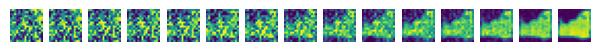

Epoch 1 | step 000 Loss: 0.11755191534757614 


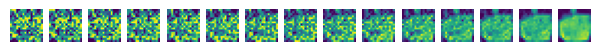

Epoch 1 | step 100 Loss: 0.10641250759363174 


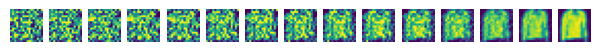

Epoch 1 | step 200 Loss: 0.12456037849187851 


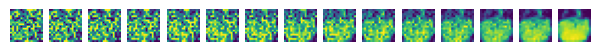

Epoch 1 | step 300 Loss: 0.11045652627944946 


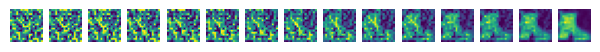

Epoch 1 | step 400 Loss: 0.10222354531288147 


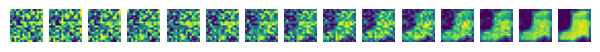

Epoch 1 | step 500 Loss: 0.10228046774864197 


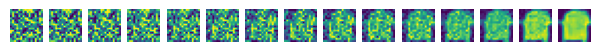

Epoch 2 | step 000 Loss: 0.10820281505584717 


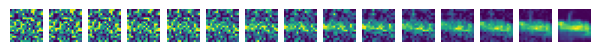

Epoch 2 | step 100 Loss: 0.0952083170413971 


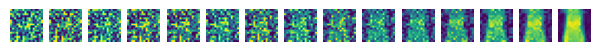

Epoch 2 | step 200 Loss: 0.11691649258136749 


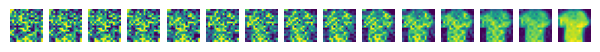

Epoch 2 | step 300 Loss: 0.09322898089885712 


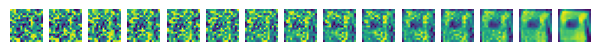

Epoch 2 | step 400 Loss: 0.10437586903572083 


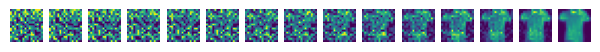

Epoch 2 | step 500 Loss: 0.09602554142475128 


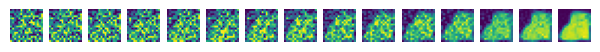

Epoch 3 | step 000 Loss: 0.11051569879055023 


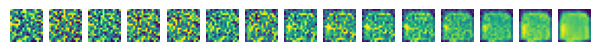

Epoch 3 | step 100 Loss: 0.08803260326385498 


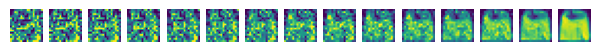

Epoch 3 | step 200 Loss: 0.09216167032718658 


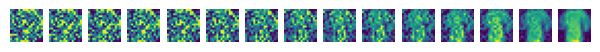

Epoch 3 | step 300 Loss: 0.09832251816987991 


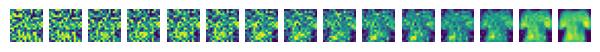

Epoch 3 | step 400 Loss: 0.10516621172428131 


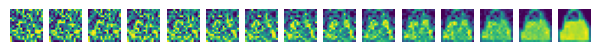

Epoch 3 | step 500 Loss: 0.07848276197910309 


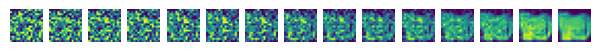

Epoch 4 | step 000 Loss: 0.09832873940467834 


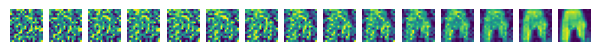

Epoch 4 | step 100 Loss: 0.07817451655864716 


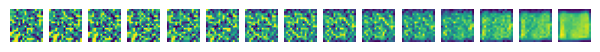

Epoch 4 | step 200 Loss: 0.0901493951678276 


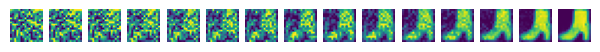

Epoch 4 | step 300 Loss: 0.1085997074842453 


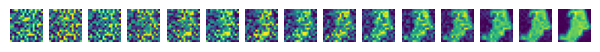

Epoch 4 | step 400 Loss: 0.09861615300178528 


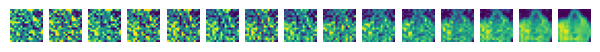

Epoch 4 | step 500 Loss: 0.0949505865573883 


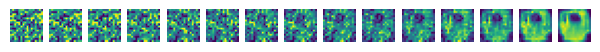

In [17]:
optimizer = Adam(model.parameters(), lr=0.001)
epochs = 5

model.train()
for epoch in range(epochs):
    for step, batch in enumerate(dataloader):
        optimizer.zero_grad()

        t = torch.randint(0, T, (BATCH_SIZE,), device=device).float()
        x = batch[0].to(device)
        loss = ddpm.get_loss(model, x, t)
        loss.backward()
        optimizer.step()

        if epoch % 1 == 0 and step % 100 == 0:
            print(f"Epoch {epoch} | step {step:03d} Loss: {loss.item()} ")
            ddpm.sample_images(model, IMG_CH, IMG_SIZE, ncols)

How about a closer look? Can you recognize a shoe, a purse, or a shirt?

<Figure size 800x800 with 0 Axes>

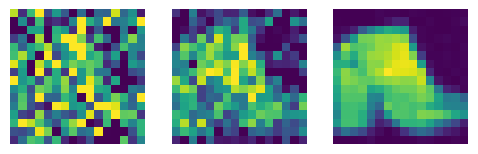

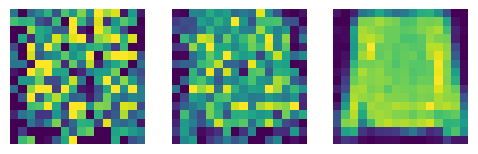

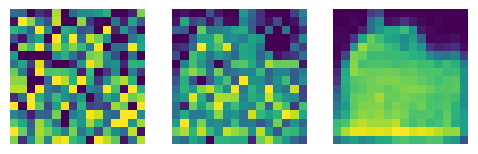

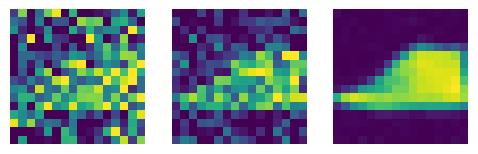

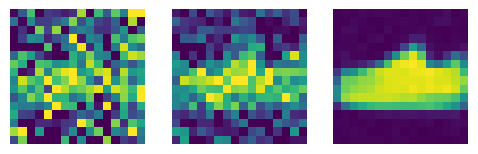

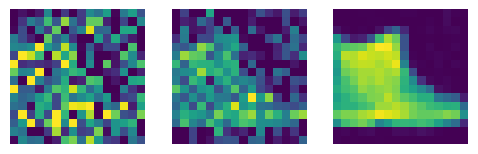

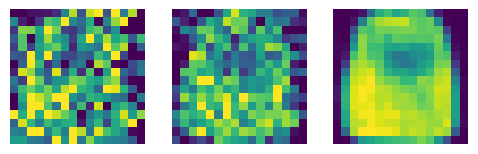

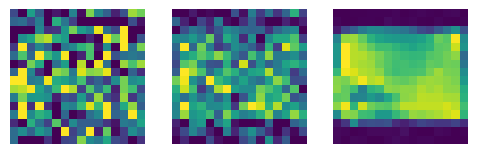

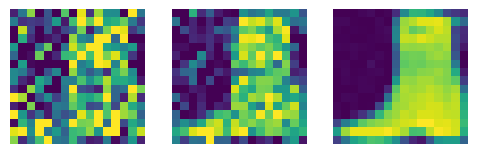

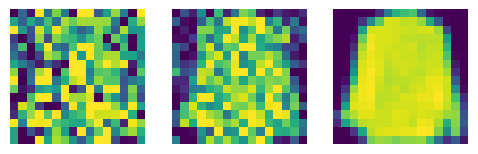

In [19]:
model.eval()
plt.figure(figsize=(8,8))
ncols = 3 # Should evenly divide T
for _ in range(10):
    ddpm.sample_images(model, IMG_CH, IMG_SIZE, ncols)

## 3.5 Next

If you don't see a particular class such as a shoe or a shirt, try running the above code block again. Currently, our model does not accept category input, so the user can't define what kind of output they would like. Where's the fun in that?

In the next notebook, we will finally add a way for users to control the model!

In [ ]:
import IPython
app = IPython.Application.instance()
app.kernel.do_shutdown(True)

<center><a href="https://www.nvidia.com/en-us/training/"><img src="https://dli-lms.s3.amazonaws.com/assets/general/DLI_Header_White.png" width="400" height="186" /></a></center>